# Chapter 36: Vertical Control, Foreclosure, Integration, and Hold-Up

This notebook reruns four worked examples from the chapter: double marginalization between a channel owner and a platform, exclusive dealing as a coordination failure, raising a rival's cost in a Cournot duopoly, and the make-or-buy choice as volume changes. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def double_marginalization(a, c, structure="separate"):
    """double-marginalization: demand Q = a - p, upstream marginal cost c.

    structure "separate": w = (a + c) / 2, p = (a + w) / 2; "integrated": p = (a + c) / 2;
    "competitive": downstream p = w and upstream sets w = (a + c) / 2. Book (ch036):
    a = 100, c = 10 gives w = 55, p = 77.50, Q = 22.5, upstream 1,012.50, downstream 506.25,
    joint 1,518.75; integrated p = 55, Q = 45, profit 2,025.
    """
    if structure == "separate":
        w = (a + c) / 2
        p = (a + w) / 2
    elif structure == "integrated":
        w = c
        p = (a + c) / 2
    elif structure == "competitive":
        w = (a + c) / 2
        p = w
    else:
        raise ValueError(structure)
    Q = a - p
    up = (w - c) * Q
    down = (p - w) * Q
    return {"w": w, "p": p, "Q": Q, "upstream": up, "downstream": down, "joint": up + down}


def exclusive_dealing(n, units, threshold, signers, payment=100, saving=50):
    """exclusive-dealing-foreclosure: n distributors of `units` purchases each.

    Entry needs `threshold` open units. Book (ch036): 10 x 10, threshold 60, five signers leave
    50 open units, so entry is blocked; six rejecters gain 6(500) = 3,000 against 6(100) = 600.
    """
    open_units = (n - signers) * units
    entry = open_units >= threshold
    coalition = math.ceil(threshold / units)
    return {"open": open_units, "entry": entry, "coalition": coalition,
            "coalition_gain": coalition * units * saving, "coalition_payments": coalition * payment}


def cournot_two(a, c1, c2):
    """raising-rivals-costs: Cournot duopoly with P = a - Q1 - Q2 (interior solution).

    Book (ch036): a = 100, costs 20 and 35 give Q_D = 31.67, Q_R = 16.67, P = 51.67;
    20 and 20 give 26.67 each and profit 711.11; 30 and 35 give 25, 20, P = 55.
    """
    q1 = max((a - 2 * c1 + c2) / 3, 0.0)
    q2 = max((a - 2 * c2 + c1) / 3, 0.0)
    if q1 == 0 or q2 == 0:
        raise ValueError("corner solution not modelled")
    p = a - q1 - q2
    return {"q1": q1, "q2": q2, "P": p, "profit1": (p - c1) * q1, "profit2": (p - c2) * q2}


def make_or_buy(V, price=40, contracting=400_000, hazard=600_000, setup=1_800_000, unit=28, admin=300_000):
    """vertical-integration: market cost C_M = V p + contracting + hazard; internal C_I = setup + V c + admin.

    Book (ch036): at 100,000 units C_M = 5.0 million, C_I = 4.9 million; at 50,000, 3.0 and 3.5 million.
    """
    cm = V * price + contracting + hazard
    ci = setup + V * unit + admin
    crossover = (setup + admin - contracting - hazard) / (price - unit)
    return {"market": cm, "internal": ci, "saving": cm - ci, "crossover": crossover}


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(double_marginalization=double_marginalization, exclusive_dealing=exclusive_dealing, cournot_two=cournot_two)


production = SimpleNamespace(make_or_buy=make_or_buy)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'double-marginalization': {'a': 100,
                            'c': 10,
                            'w': 55,
                            'p': 77.5,
                            'Q': 22.5,
                            'upstream': 1012.5,
                            'downstream': 506.25,
                            'joint': 1518.75,
                            'p_int': 55,
                            'Q_int': 45,
                            'profit_int': 2025,
                            'price_gap': 22.5,
                            'joint_gain': 506.25},
 'exclusive-dealing-foreclosure': {'n': 10,
                                   'units': 10,
                                   'threshold': 60,
                                   'payment': 100,
                                   'saving': 50,
                                   'signers': 5,
                                   'open': 50,
                                   'coalition_gain': 3000,
                                   'coalition_payments': 600,
                                   'threshold_low': 40},
 'raising-rivals-costs': {'a': 100,
                          'c': 20,
                          'q_base': 26.67,
                          'p_base': 46.67,
                          'profit_base': 711.11,
                          'c_r': 35,
                          'contract': 100,
                          'q_d': 31.67,
                          'q_r': 16.67,
                          'p': 51.67,
                          'gross': 1002.78,
                          'net': 902.78,
                          'gain': 191.67,
                          'c_d_high': 30,
                          'q_d_high': 25,
                          'q_r_high': 20,
                          'p_high': 55,
                          'gross_high': 625,
                          'net_high': 525},
 'vertical-integration': {'V': 100000,
                          'price': 40,
                          'contracting': 400000,
                          'hazard': 600000,
                          'setup': 1800000,
                          'unit': 28,
                          'admin': 300000,
                          'market': 5000000,
                          'internal': 4900000,
                          'saving': 100000,
                          'V_low': 50000,
                          'market_low': 3000000,
                          'internal_low': 3500000},
 'constructed': {'double-marginalization': {'c': [0, 20, 40]},
                 'exclusive-dealing-foreclosure': {'threshold': [80], 'signers': [3, 7]},
                 'raising-rivals-costs': {'c_r': [27.5, 45], 'c_d': [25]},
                 'vertical-integration': {'V': [75000, 150000]}}}


STRUCTURES = {"separate": "Separate firms", "integrated": "Integrated", "competitive": "Competitive retail"}


def dm_picture(c=10, s="separate"):
    res = {k: industrial.double_marginalization(100, c, k) for k in STRUCTURES}
    r = res[s]
    fig, (ax, bx) = new_figure(ncols=2)
    qs = np.linspace(0, 100, 50)
    ax.plot(qs, 100 - qs, color=PALETTE["navy"], linewidth=2.2, label="demand p = 100 - Q")
    ax.axhline(c, color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    label(ax, 62, c, f"upstream cost {c}", col="grey", dx=0, dy=4)
    sep, integ = res["separate"], res["integrated"]
    mark(ax, sep["Q"], sep["p"], f"separate: p = {num(sep['p'])}", col="terracotta" if s == "separate" else "grey",
         dx=8, dy=6)
    mark(ax, integ["Q"], integ["p"], f"one markup: p = {num(integ['p'])}",
         col="teal" if s != "separate" else "grey", dx=8, dy=6)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 110)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Subscriptions Q")
    ax.set_ylabel("Retail price p ($)")
    names = ["Separate", "Integrated", "Competitive"]
    stacked_bar(bx, names, [[res[k]["upstream"] for k in STRUCTURES], [res[k]["downstream"] for k in STRUCTURES]],
                ["upstream profit", "downstream profit"], colors=["navy", "gold"], ylabel="Profit ($)",
                total_marker=False)
    for i, k in enumerate(STRUCTURES):
        bx.annotate(f"joint {num(res[k]['joint'])}", (i, res[k]["joint"]), xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10.5, color=PALETTE["ink"])
    bx.set_ylim(0, max(x["joint"] for x in res.values()) * 1.3 + 1)
    bx.set_xlim(-0.6, 2.6)
    bx.legend(loc="upper left", frameon=False)
    bx.set_xlabel("Structure")
    gap = sep["p"] - integ["p"]
    metrics = {"Wholesale fee w": num(r["w"]), "Retail price p": num(r["p"]), "Quantity Q": num(r["Q"]),
               "Upstream profit": money(r["upstream"]), "Downstream profit": money(r["downstream"]),
               "Joint profit": money(r["joint"]), "Price gap, separate minus integrated": money(gap)}
    if s == "separate":
        body = (f"The channel owner sets w = (100 + {c}) / 2 = {num(r['w'])}; the platform charges p = (100 + "
                f"{num(r['w'])}) / 2 = {num(r['p'])} and sells Q = 100 - {num(r['p'])} = {num(r['Q'])}. Upstream earns "
                f"{num(r['w'] - c)} x {num(r['Q'])} = {money(r['upstream'])}, downstream {num(r['p'] - r['w'])} x "
                f"{num(r['Q'])} = {money(r['downstream'])}, joint {money(r['joint'])}, below the integrated "
                f"{money(integ['joint'])}.")
        steps = [f"w = (100 + {c}) / 2 = {num(r['w'])}", f"p = (100 + {num(r['w'])}) / 2 = {num(r['p'])}",
                 f"Q = 100 - {num(r['p'])} = {num(r['Q'])}",
                 f"Upstream = {num(r['w'] - c)} x {num(r['Q'])} = {money(r['upstream'])}",
                 f"Downstream = {num(r['p'] - r['w'])} x {num(r['Q'])} = {money(r['downstream'])}",
                 f"Joint = {money(r['upstream'])} + {money(r['downstream'])} = {money(r['joint'])}"]
    elif s == "integrated":
        body = (f"One owner maximizes (p - {c})(100 - p), so p = (100 + {c}) / 2 = {num(r['p'])} and Q = "
                f"{num(r['Q'])}. Profit is {num(r['p'] - c)} x {num(r['Q'])} = {money(r['joint'])}, "
                f"{money(r['joint'] - sep['joint'])} more than separate firms earn, at a price {money(gap)} lower.")
        steps = [f"p = (100 + {c}) / 2 = {num(r['p'])}", f"Q = 100 - {num(r['p'])} = {num(r['Q'])}",
                 f"Profit = {num(r['p'] - c)} x {num(r['Q'])} = {money(r['joint'])}",
                 f"Gain over separate = {money(r['joint'])} - {money(sep['joint'])} = {money(r['joint'] - sep['joint'])}"]
    else:
        body = (f"Competing platforms force p = w, so the owner picks the final price directly: w = p = (100 + {c}) / "
                f"2 = {num(r['p'])}, Q = {num(r['Q'])}, and upstream profit is {num(r['w'] - c)} x {num(r['Q'])} = "
                f"{money(r['upstream'])}. There is no second markup.")
        steps = [f"p = w = (100 + {c}) / 2 = {num(r['p'])}", f"Q = 100 - {num(r['p'])} = {num(r['Q'])}",
                 f"Upstream = {num(r['w'] - c)} x {num(r['Q'])} = {money(r['upstream'])}",
                 "Downstream margin p - w = 0.00"]
    interp = body
    alt = (f"Demand p = 100 - Q with the separate-firm price {num(sep['p'])} and the integrated price "
           f"{num(integ['p'])} at upstream cost {c}; bars compare profits across the three structures.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def exclusive_picture(t=60, k=5):
    bv = BV["exclusive-dealing-foreclosure"]
    res = industrial.exclusive_dealing(bv["n"], bv["units"], t, k, bv["payment"], bv["saving"])
    fig, ax = new_figure()
    for i in range(10):
        signed_block = i >= 10 - k
        ax.barh(0, 10, left=10 * i, color=PALETTE["terracotta"] if signed_block else PALETTE["teal"],
                edgecolor="white", height=0.6)
    vline(ax, t, f"entry threshold {t}", col="ink", y_frac=0.93, ha="right" if t >= 70 else "left")
    label(ax, 1, -0.5, f"open: {num(res['open'], 0)} units", col="teal", dx=0, dy=0, va="top")
    label(ax, 99, -0.5, f"signed: {k * 10} units", col="terracotta", dx=0, dy=0, ha="right", va="top")
    ax.set_xlim(0, 100)
    ax.set_ylim(-1, 1)
    ax.set_yticks([])
    ax.set_xlabel("Purchases, ten per distributor (open first, then signed)")
    ax.set_ylabel("Distributors")
    m = res["coalition"]
    outcome = ("entry happens" if res["entry"] else "entry is blocked")
    metrics = {"Open units": num(res["open"], 0), "Entry": "occurs" if res["entry"] else "blocked",
               "Smallest rejecting coalition": plural(m, "distributor"),
               "Coalition buyer gain": money(res["coalition_gain"], 0),
               "Coalition payments given up": money(res["coalition_payments"], 0)}
    comp = (f"{num(res['open'], 0)} is at least {t}" if res["entry"] else f"{num(res['open'], 0)} is below {t}")
    interp = (f"With {k} of 10 distributors signed, {10 - k} x 10 = {num(res['open'], 0)} units stay open; {comp}, so "
              f"{outcome}. A single distributor that expects the others to sign cannot reach {t} units alone, so taking "
              f"the $100 is individually rational. Yet {plural(m, 'distributor')} rejecting together would open "
              f"{m * 10} units and gain {m} x $500 = {money(res['coalition_gain'], 0)}, against "
              f"{m} x $100 = {money(res['coalition_payments'], 0)} in payments.")
    steps = [f"Open units = (10 - {k}) x 10 = {num(res['open'], 0)}",
             f"{comp}: {outcome}",
             f"Coalition size = {t} / 10 = {m}",
             f"Coalition gain = {m} x 10 x $50 = {money(res['coalition_gain'], 0)}",
             f"Payments given up = {m} x $100 = {money(res['coalition_payments'], 0)}"]
    alt = (f"Ten blocks of ten purchases: {10 - k} open and {k} signed, with the entry threshold at {t} units; "
           f"{outcome}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def rrc_picture(cr=35, cd=20):
    bv = BV["raising-rivals-costs"]
    base = industrial.cournot_two(100, 20, 20)
    r = industrial.cournot_two(100, cd, cr)
    net = r["profit1"] - bv["contract"]
    gain = round(net, 2) - 711.11  # the baseline 711.11 is the book's printed (80/3)^2
    fig, ax = new_figure()
    qr = np.linspace(0, 80, 100)
    ax.plot((100 - cd - qr) / 2, qr, color=PALETTE["navy"], linewidth=2.2, label="D's best response")
    qd = np.linspace(0, 80, 100)
    ax.plot(qd, (100 - cr - qd) / 2, color=PALETTE["gold"], linewidth=2.2, label="R's best response")
    mark(ax, base["q1"], base["q2"], "no contract (26.67, 26.67)", col="grey", dx=8, dy=8)
    mark(ax, r["q1"], r["q2"], f"contract ({num(r['q1'])}, {num(r['q2'])})", col="terracotta", dx=8, dy=-12, va="top")
    ax.set_xlim(0, 60)
    ax.set_ylim(0, 60)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Output of D, Q_D")
    ax.set_ylabel("Output of R, Q_R")
    pays = net > base["profit1"] + 1e-9
    verdict = ("The contract pays" if pays else "The contract does not pay")
    metrics = {"Q_D": num(r["q1"]), "Q_R": num(r["q2"]), "Price P": num(r["P"]),
               "D's profit before contract": money(r["profit1"]), "D's net profit": money(net),
               "Gain over 711.11 baseline": money(gain) if gain >= 0 else f"-{money(-gain)}"}
    def g(x):
        return num(x, 0) if float(x).is_integer() else num(x, 1)
    n_d, n_r, n_p = 100 - 2 * cd + cr, 100 - 2 * cr + cd, 100 + cd + cr
    interp = (f"Q_D = (100 - 2 x {g(cd)} + {g(cr)}) / 3 = {g(n_d)} / 3 = {num(r['q1'])} and Q_R = (100 - 2 x "
              f"{g(cr)} + {g(cd)}) / 3 = {g(n_r)} / 3 = {num(r['q2'])}, so P = (100 + {g(cd)} + {g(cr)}) / 3 = "
              f"{g(n_p)} / 3 = {num(r['P'])}. Because P - c_D = Q_D, D earns Q_D^2 = {num(n_d * n_d, 2)} / 9 = "
              f"{money(r['profit1'])}, or {money(net)} after the $100 contract. {verdict}: the baseline with both "
              f"costs at 20 is $711.11, so the change is {signed(net - 711.11)}.")
    steps = [f"Q_D = (100 - 2 x {g(cd)} + {g(cr)}) / 3 = {g(n_d)} / 3 = {num(r['q1'])}",
             f"Q_R = (100 - 2 x {g(cr)} + {g(cd)}) / 3 = {g(n_r)} / 3 = {num(r['q2'])}",
             f"P = (100 + {g(cd)} + {g(cr)}) / 3 = {g(n_p)} / 3 = {num(r['P'])}",
             f"D's profit = Q_D^2 = {num(n_d * n_d, 2)} / 9 = {num(r['profit1'])}",
             f"Net = {num(r['profit1'])} - 100 = {num(net)}",
             f"Change from 711.11 = {num(net)} - 711.11 = {signed(net - 711.11)}"]
    alt = (f"Cournot best-response lines for D with cost {num(cd, 2)} and R with cost {num(cr, 2)}; they cross at "
           f"Q_D = {num(r['q1'])} and Q_R = {num(r['q2'])}, compared with 26.67 each without the contract.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def mob_picture(v=100_000):
    res = production.make_or_buy(v)
    vs = np.linspace(0, 160_000, 100)
    fig, ax = new_figure()
    ax.plot(vs / 1000, [production.make_or_buy(x)["market"] / 1e6 for x in vs], color=PALETTE["navy"], linewidth=2.2,
            label="buy: C_M = 40V + 1.0 million")
    ax.plot(vs / 1000, [production.make_or_buy(x)["internal"] / 1e6 for x in vs], color=PALETTE["teal"], linewidth=2.2,
            label="make: C_I = 28V + 2.1 million")
    vline(ax, res["crossover"] / 1000, f"break-even {num(res['crossover'], 0)}", col="grey", y_frac=0.75)
    mark(ax, v / 1000, res["market"] / 1e6, None, col="navy")
    mark(ax, v / 1000, res["internal"] / 1e6, None, col="teal")
    ax.set_xlim(0, 160)
    ax.set_ylim(0, 8)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Annual volume (thousand units)")
    ax.set_ylabel("Expected annual cost ($ million)")
    save = res["saving"]
    choice = "making in house is cheaper" if save > 0 else ("buying is cheaper" if save < 0 else "the two tie")
    metrics = {"Market cost C_M": money(res["market"], 0), "Internal cost C_I": money(res["internal"], 0),
               "Saving from integration": money(save, 0) if save >= 0 else f"-{money(-save, 0)}",
               "Break-even volume": num(res["crossover"], 0)}
    interp = (f"In dollars, C_M = {num(v, 0)} x 40 + 400,000 + 600,000 = {num(res['market'], 0)} and C_I = 1,800,000 + "
              f"{num(v, 0)} x 28 + 300,000 = {num(res['internal'], 0)}. The difference is {money(abs(save), 0)}, so "
              f"{choice}. Making wins above {num(res['crossover'], 0)} units, where the $12 unit saving covers the "
              f"$1,100,000 net fixed cost.")
    steps = [f"C_M = {num(v, 0)} x 40 + 400,000 + 600,000 = {money(res['market'], 0)}",
             f"C_I = 1,800,000 + {num(v, 0)} x 28 + 300,000 = {money(res['internal'], 0)}",
             f"C_M - C_I = {signed(save, 0)}",
             f"Break-even: 1,100,000 / 12 = {num(res['crossover'], 0)} units"]
    alt = (f"Expected cost of buying and of making against volume; the lines cross at {num(res['crossover'], 0)} units. "
           f"At {num(v, 0)} units buying costs {money(res['market'], 0)} and making {money(res['internal'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Double marginalization: two markups or one

Demand is $Q=100-p$ and the channel owner's cost is 10. Given the wholesale fee $w$ the platform chooses

$$p=\frac{100+w}{2},\qquad Q=\frac{100-w}{2}.$$

An integrated firm solves $$\max_p (p-10)(100-p).$$

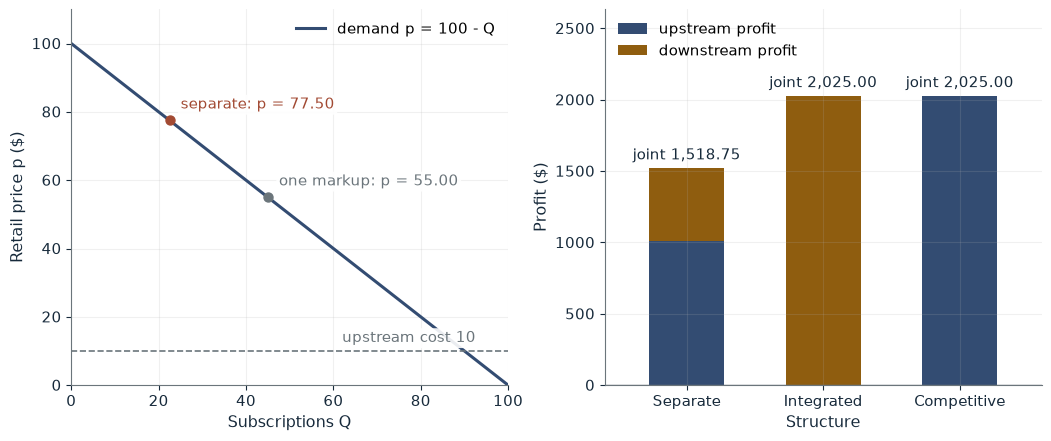

Wholesale fee w                       55.00
Retail price p                        77.50
Quantity Q                            22.50
Upstream profit                       $1,012.50
Downstream profit                     $506.25
Joint profit                          $1,518.75
Price gap, separate minus integrated  $22.50

Worked steps:
  1. w = (100 + 10) / 2 = 55.00
  2. p = (100 + 55.00) / 2 = 77.50
  3. Q = 100 - 77.50 = 22.50
  4. Upstream = 45.00 x 22.50 = $1,012.50
  5. Downstream = 22.50 x 22.50 = $506.25
  6. Joint = $1,012.50 + $506.25 = $1,518.75

The channel owner sets w = (100 + 10) / 2 = 55.00; the platform charges p = (100 + 55.00) / 2 = 77.50 and sells Q = 100 - 77.50 = 22.50. Upstream earns 45.00 x 22.50 = $1,012.50, downstream 22.50 x 22.50 = $506.25, joint $1,518.75, below the integrated $2,025.00.


In [2]:
show(dm_picture(c=10, s='separate'))

Change one input, `s`, and hold the others at the book's values:

In [3]:
sweep(dm_picture, 's', ['separate', 'integrated', 'competitive'], {'c': 10}, ['Retail price p', 'Quantity Q', 'Joint profit'])

s | Retail price p | Quantity Q | Joint profit
separate | 77.50 | 22.50 | $1,518.75
integrated | 55.00 | 45.00 | $2,025.00
competitive | 55.00 | 45.00 | $2,025.00


Separate firms charge 77.50, sell 22.5 and earn \$1,518.75 together; one markup gives 55, 45 and \$2,025. With competitive retail the owner sets the final price directly and there is no second markup.

## 2. Exclusive-dealing foreclosure: a coordination failure

Ten distributors each represent ten purchases; entry needs 60 open units. Six rejecting together would gain

$$6(\$500)=\$3{,}000,$$

against \$600 in exclusivity payments.

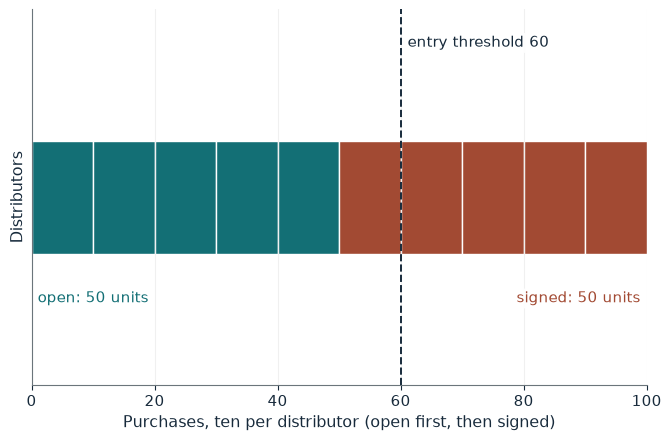

Open units                    50
Entry                         blocked
Smallest rejecting coalition  6 distributors
Coalition buyer gain          $3,000
Coalition payments given up   $600

Worked steps:
  1. Open units = (10 - 5) x 10 = 50
  2. 50 is below 60: entry is blocked
  3. Coalition size = 60 / 10 = 6
  4. Coalition gain = 6 x 10 x $50 = $3,000
  5. Payments given up = 6 x $100 = $600

With 5 of 10 distributors signed, 5 x 10 = 50 units stay open; 50 is below 60, so entry is blocked. A single distributor that expects the others to sign cannot reach 60 units alone, so taking the $100 is individually rational. Yet 6 distributors rejecting together would open 60 units and gain 6 x $500 = $3,000, against 6 x $100 = $600 in payments.


In [4]:
show(exclusive_picture(t=60, k=5))

Change one input, `t`, and hold the others at the book's values:

In [5]:
sweep(exclusive_picture, 't', [40, 60, 80], {'k': 5}, ['Open units', 'Entry', 'Coalition buyer gain'])

t | Open units | Entry | Coalition buyer gain
40 | 50 | occurs | $2,000
60 | 50 | blocked | $3,000
80 | 50 | blocked | $4,000


Five exclusives leave 50 open units, below 60, so entry is blocked even though the rejecting coalition would gain far more than the payments. With a 40-unit threshold entry happens.

## 3. Raising rivals' costs

Inverse demand is $P=100-Q_D-Q_R$ and both costs start at 20:

$$Q_D=Q_R=\frac{100-2(20)+20}{3}=26.67.$$

A \$100 contract raises the rival's cost to 35, giving

$$Q_D=31.67,\qquad Q_R=16.67.$$

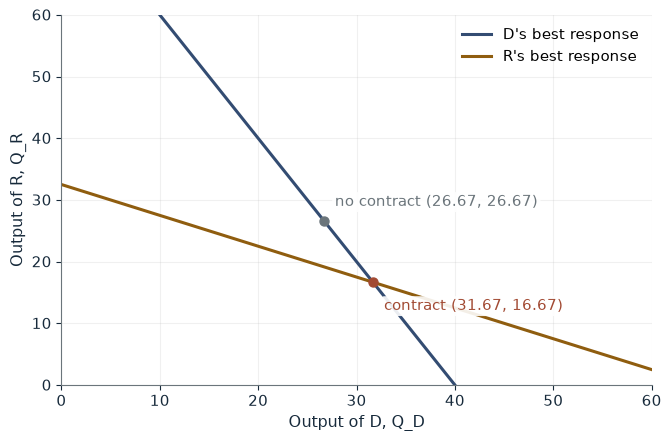

Q_D                         31.67
Q_R                         16.67
Price P                     51.67
D's profit before contract  $1,002.78
D's net profit              $902.78
Gain over 711.11 baseline   $191.67

Worked steps:
  1. Q_D = (100 - 2 x 20 + 35) / 3 = 95 / 3 = 31.67
  2. Q_R = (100 - 2 x 35 + 20) / 3 = 50 / 3 = 16.67
  3. P = (100 + 20 + 35) / 3 = 155 / 3 = 51.67
  4. D's profit = Q_D^2 = 9,025.00 / 9 = 1,002.78
  5. Net = 1,002.78 - 100 = 902.78
  6. Change from 711.11 = 902.78 - 711.11 = 191.67

Q_D = (100 - 2 x 20 + 35) / 3 = 95 / 3 = 31.67 and Q_R = (100 - 2 x 35 + 20) / 3 = 50 / 3 = 16.67, so P = (100 + 20 + 35) / 3 = 155 / 3 = 51.67. Because P - c_D = Q_D, D earns Q_D^2 = 9,025.00 / 9 = $1,002.78, or $902.78 after the $100 contract. The contract pays: the baseline with both costs at 20 is $711.11, so the change is 191.67.


In [6]:
show(rrc_picture(cr=35, cd=20))

Change one input, `cd`, and hold the others at the book's values:

In [7]:
sweep(rrc_picture, 'cd', [20, 25, 30], {'cr': 35}, ['Q_D', 'Price P', "D's net profit"])

cd | Q_D | Price P | D's net profit
20 | 31.67 | 51.67 | $902.78
25 | 28.33 | 53.33 | $702.78
30 | 25.00 | 55.00 | $525.00


D nets \$902.78, \$191.67 above the \$711.11 baseline. If its own cost also rises to 30, it nets only \$525 and the strategy fails.

## 4. Vertical integration: make or buy by volume

$$C_M=100{,}000(\$40)+\$400{,}000+\$600{,}000=\$5.0\text{ million}.$$

$$C_I=\$1.8\text{ million}+100{,}000(\$28)+\$300{,}000=\$4.9\text{ million}.$$

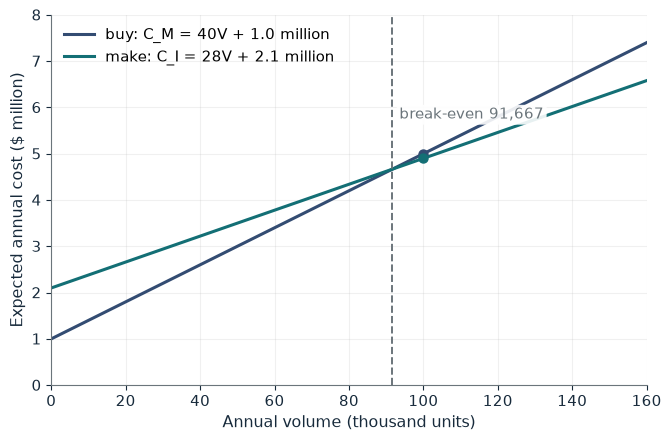

Market cost C_M          $5,000,000
Internal cost C_I        $4,900,000
Saving from integration  $100,000
Break-even volume        91,667

Worked steps:
  1. C_M = 100,000 x 40 + 400,000 + 600,000 = $5,000,000
  2. C_I = 1,800,000 + 100,000 x 28 + 300,000 = $4,900,000
  3. C_M - C_I = 100,000
  4. Break-even: 1,100,000 / 12 = 91,667 units

In dollars, C_M = 100,000 x 40 + 400,000 + 600,000 = 5,000,000 and C_I = 1,800,000 + 100,000 x 28 + 300,000 = 4,900,000. The difference is $100,000, so making in house is cheaper. Making wins above 91,667 units, where the $12 unit saving covers the $1,100,000 net fixed cost.


In [8]:
show(mob_picture(v=100_000))

Change one input, `v`, and hold the others at the book's values:

In [9]:
sweep(mob_picture, 'v', [50000, 75000, 100000, 150000], {}, ['Market cost C_M', 'Internal cost C_I', 'Saving from integration'])

v | Market cost C_M | Internal cost C_I | Saving from integration
50000 | $3,000,000 | $3,500,000 | -$500,000
75000 | $4,000,000 | $4,200,000 | -$200,000
100000 | $5,000,000 | $4,900,000 | $100,000
150000 | $7,000,000 | $6,300,000 | $700,000


Making saves \$100,000 at 100,000 units but loses \$500,000 at 50,000. The two costs cross at 1,100,000 / 12 = 91,667 units.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

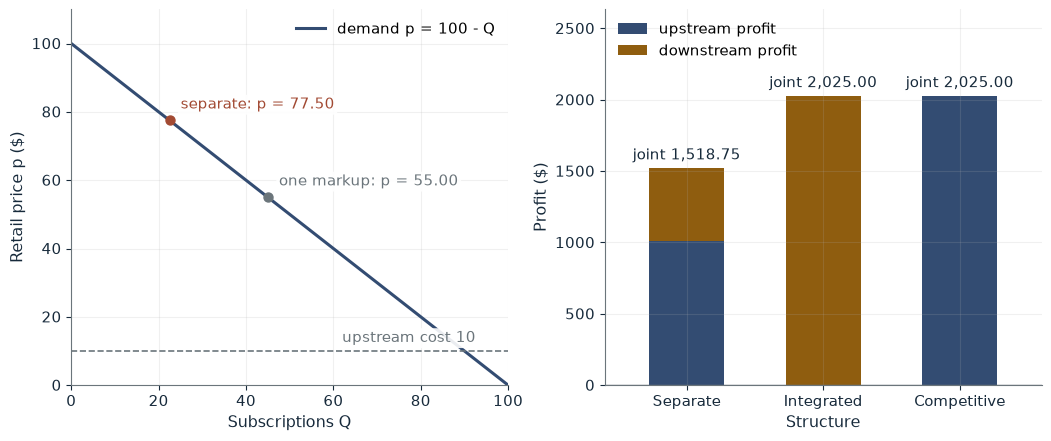

Wholesale fee w                       55.00
Retail price p                        77.50
Quantity Q                            22.50
Upstream profit                       $1,012.50
Downstream profit                     $506.25
Joint profit                          $1,518.75
Price gap, separate minus integrated  $22.50

Worked steps:
  1. w = (100 + 10) / 2 = 55.00
  2. p = (100 + 55.00) / 2 = 77.50
  3. Q = 100 - 77.50 = 22.50
  4. Upstream = 45.00 x 22.50 = $1,012.50
  5. Downstream = 22.50 x 22.50 = $506.25
  6. Joint = $1,012.50 + $506.25 = $1,518.75

The channel owner sets w = (100 + 10) / 2 = 55.00; the platform charges p = (100 + 55.00) / 2 = 77.50 and sells Q = 100 - 77.50 = 22.50. Upstream earns 45.00 x 22.50 = $1,012.50, downstream 22.50 x 22.50 = $506.25, joint $1,518.75, below the integrated $2,025.00.


In [10]:
show(dm_picture(c=10, s='separate'))

## Practice

**1.** At upstream cost 20 with separate firms, what are w, p and joint profit?

<details><summary>Answer</summary>

w = 60, p = 80, Q = 20; upstream 40 x 20 = 800, downstream 20 x 20 = 400, joint 1,200 against 40^2 = 1,600 integrated.

</details>

**2.** Threshold 80 with 3 signers: does entry occur?

<details><summary>Answer</summary>

Open units = 7 x 10 = 70, below 80, so entry is blocked.

</details>

**3.** At 150,000 units, how much does integration save?

<details><summary>Answer</summary>

C_M = 6,000,000 + 1,000,000 = 7,000,000 and C_I = 1,800,000 + 4,200,000 + 300,000 = 6,300,000, a saving of 700,000.

</details>